# Pipeline de Predicción de Churn Bancario (Agosto 2021) — v3 corregida

Versión corregida de `churn_pipeline.ipynb`. Mismas etapas y mismo código de cátedra de base
(`z101`, `z201`, `z301`, `z401`, `z402`, `z501`, `z701`, `exp_401`, `exp_402`), con estas correcciones:

| # | Problema en la versión anterior | Corrección en esta versión |
|---|---|---|
| 1 | Las celdas de gráficos usaban `tabla_ganancia` antes de crearla → "Run All" fallaba | Orden lineal: el notebook corre de punta a punta |
| 2 | `COLS_EXCLUIR_SIEMPRE` no sacaba `lag/delta_cprestamos_personales`, ni `prestamos_total` / `ratio_deuda_ingreso` (que contienen préstamos personales y payroll) | La exclusión se propaga sola a lags/deltas y a las variables derivadas (Etapa 5) |
| 3 | `lag2_`/`delta2_` de 202104 se completaban con la mediana → datos inventados indistinguibles de los reales | RF: imputer con `add_indicator=True` (marca qué valor fue imputado). LightGBM: usa los NaN de forma nativa |
| 4 | 202106 se usaba para Optuna **y** para el corte, y el modelo final nunca se reentrenaba (predecía agosto con abril–mayo) | 202106 sólo elige hiperparámetros y cantidad de envíos; el modelo final se **reentrena con 202103–202106** (Etapa 9) |
| 5 | Optuna evaluaba la ganancia con un umbral fijo de 0.025 (premia calibración, no orden) | Optuna maximiza la ganancia máxima de la curva **suavizada**, sin umbral |
| 6 | `MedianPruner` sin `trial.report` (no podaba nada); nombres de `.db` inconsistentes | Sin pruner; un `.db` por experimento con nombre único; los trials se retoman solos |
| 7 | Corte = argmax de una curva muy ruidosa | Corte = argmax de la curva suavizada (media móvil) + se informa la meseta |
| 8 | 202103 tiene target completo pero no se usaba para entrenar | 202103 entra al train (configurable con `MESES_TRAIN`) |
| — | Chequeo de hueco en lags con `foto_mes - lag = 1` (falla al cruzar de año) | Se compara en "períodos" (año*12 + mes) |
| — | Se excluían `*_mlimitecompra_real` por drift, pero quedaba `tc_limite_total` con la misma info | Derivadas de una variable con drift se excluyen si su propio PSI está en alerta |
| — | `cluster` entraba como número ordinal (1–5) | Se reemplaza por dummies `cluster_1..k` |
| — | El semillero reusaba las semillas de Optuna | Semillas disjuntas |

**Novedad — Etapa 6 compara 3 experimentos con el mismo objetivo:** RF ternario (el anterior),
RF binario (BAJA+1 ∪ BAJA+2 = positivo) y LightGBM binario. El ganador sigue al semillero, al corte
y a la predicción final. La ganancia siempre se mide **sólo sobre BAJA+2**, sea cual sea el target de entrenamiento.

**Roles de cada mes:**
- **Histórico** (202107): sólo para lags/deltas de agosto.
- **Train** (202103 + 202104 + 202105): target maduro y completo.
- **Validación** (202106): elige hiperparámetros, modelo ganador y cantidad de envíos.
- **Final** (202103–202106): reentrenamiento con los hiperparámetros elegidos.
- **Aplicación** (202108): mes del desafío, `clase_ternaria == 'SIN CLASE'`.

In [1]:
# Si falta alguna librería, descomentá:
# %pip install duckdb optuna lightgbm --quiet

import os
import json
import time
import datetime

os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))  # silencia el warning de joblib en Windows

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Configuración general

`MODO_PRUEBA = True` corre todo con una muestra de clientes y pocos trials (unos minutos), para
chequear que el notebook ande de punta a punta antes de lanzar la corrida larga.

In [2]:
BASE_PATH = r"C:\Users\micaela.r.rodriguez\Documents\Mica\Personal\Data Mining\EyF"
DATASET_PATH = os.path.join(BASE_PATH, "competencia_01.csv")
MODELOS_PATH = os.path.join(BASE_PATH, "modelos")
SALIDAS_PATH = BASE_PATH
os.makedirs(MODELOS_PATH, exist_ok=True)

MODO_PRUEBA = False
FRACCION_MUESTRA = 0.05 if MODO_PRUEBA else 1.0   # fracción de CLIENTES (no de filas) que se cargan

MESES_HIST = [202107]                    # sólo para lags/deltas, no entrenan
MESES_TRAIN = [202103, 202104, 202105]   # se concatenan para el entrenamiento
MES_VALID = 202106                       # Optuna, elección de modelo y cantidad de envíos
MES_APLICACION = 202108                  # mes del desafío (SIN CLASE)
MESES_FINAL = MESES_TRAIN + [MES_VALID]  # reentrenamiento final (Etapa 9)

ID_COL = "numero_de_cliente"
MES_COL = "foto_mes"
TARGET_COL = "clase_ternaria"
ROL_COL = "rol"

COLS_NO_FEATURE = {ID_COL, MES_COL, TARGET_COL, ROL_COL}

# Constantes del negocio (idénticas en z201/z301/z401/exp_401/z701)
ganancia_acierto = 1_072_500
costo_estimulo = 27_500


def periodo(mes: int) -> int:
    """foto_mes (AAAAMM) -> número de mes correlativo (año*12 + mes). Permite
    restar meses sin romperse al cruzar de año (202201 - 202112 = 1, no 89)."""
    return (mes // 100) * 12 + mes % 100


PRIMER_MES = min(MESES_HIST + MESES_TRAIN + [MES_VALID, MES_APLICACION])

## Etapa 2 — reglas de imputación

El 99% de los nulos de este dataset están en las 22 columnas `Master_*` y 22 `Visa_*`, en bloques
parejos → no son azarosos, son clientes que no tienen esa tarjeta.

In [3]:
COLS_CERO = [
    f"{marca}_{sufijo}"
    for marca in ("Master", "Visa")
    for sufijo in (
        "mfinanciacion_limite", "msaldototal", "msaldopesos", "msaldodolares",
        "mconsumospesos", "mconsumosdolares", "mconsumototal",
        "mlimitecompra", "madelantopesos", "madelantodolares",
        "mpagado", "mpagospesos", "mpagosdolares", "mpagominimo",
        "cconsumos", "cadelantosefectivo",
    )
]
# Status/delinquency: rango real >= 0 -> centinela -1. fechaalta: rango real >= 1 -> -1 también sirve.
COLS_EXTREMO_NEG1 = [f"{marca}_{sufijo}" for marca in ("Master", "Visa")
                     for sufijo in ("status", "delinquency", "fechaalta")]
# Fvencimiento/Finiciomora/fultimo_cierre pueden ser negativos o ~0 legítimamente -> centinela alto.
CENTINELA_ALTO = 999_999
COLS_EXTREMO_ALTO = [f"{marca}_{sufijo}" for marca in ("Master", "Visa")
                     for sufijo in ("Fvencimiento", "Finiciomora", "fultimo_cierre")]

## Etapa 3 — deflactación por inflación y variables para lags

Variación mensual del IPC (INDEC, Argentina 2021), igual que `exp_402_feature_engineering_3`.

Con 202103 en train, ese mes queda con `lag1_*` y `lag2_*` vacíos (no hay 202102/202101), y
202104 con `lag2_*` vacío. No es un problema: LightGBM usa los NaN de forma nativa y el RF los
imputa marcando con un indicador que el valor fue imputado (ver Etapa 6).

In [4]:
IPC_MENSUAL = {
    202103: 4.8, 202104: 4.1, 202105: 3.3,
    202106: 3.2, 202107: 3.0, 202108: 2.5,
}

VARS_LAG = [
    "mcuentas_saldo_real", "mrentabilidad_real", "mactivos_margen_real",
    "mpasivos_margen_real", "mpayroll_real", "mprestamos_personales_real",
    "ctrx_quarter", "ctarjeta_visa_transacciones", "ctarjeta_master_transacciones",
    "chomebanking_transacciones", "cmobile_app_trx",
    "mtransferencias_emitidas_real", "mextraccion_autoservicio_real",
    "cprestamos_personales", "cproductos",
]

## Funciones auxiliares SQL

In [5]:
def _col(nombre: str) -> str:
    """Identificador entre comillas dobles (preserva mayúsculas, evita palabras reservadas)."""
    return f'"{nombre}"'


def _columnas(con, tabla: str) -> list:
    """Nombres de columna de una tabla de la conexión (sin traer datos)."""
    return con.execute(f"SELECT * FROM {tabla} LIMIT 0").df().columns.tolist()


def _periodo_sql(expr: str) -> str:
    """Versión SQL de periodo(): año*12 + mes (división entera con //)."""
    return f"(({expr} // 100) * 12 + ({expr} % 100))"


def crear_macros_sql(con: duckdb.DuckDBPyConnection) -> None:
    """Mismas macros que exp_402/z402: suma y ratio tratando NULL/0 sin romperse."""
    con.execute("CREATE OR REPLACE MACRO suma_sin_null(a, b) AS COALESCE(a, 0) + COALESCE(b, 0)")
    con.execute(
        "CREATE OR REPLACE MACRO ratio_sin_null(a, b) AS "
        "CASE WHEN COALESCE(b, 0) = 0 THEN 0 ELSE a / b END"
    )

## Etapa 1 — Estructura de Datasets (prevención de Data Leakage)

In [6]:
def construir_etapa1_sql(con: duckdb.DuckDBPyConnection, ruta: str = DATASET_PATH,
                          fraccion: float = FRACCION_MUESTRA) -> None:
    """
    Carga el csv con read_csv_auto (igual que z101_target_sql) y agrega 'rol'.
    Si fraccion < 1 (MODO_PRUEBA) se queda con una muestra de CLIENTES vía hash
    del id: así cada cliente seleccionado conserva todos sus meses y los lags
    siguen teniendo sentido.
    """
    t0 = time.time()
    filtro = ""
    if fraccion < 1:
        filtro = f"WHERE hash({_col(ID_COL)}) % 10000 < {int(fraccion * 10000)}"
    con.execute(f"CREATE OR REPLACE TABLE raw AS SELECT * FROM read_csv_auto('{ruta}') {filtro}")
    print(f"CSV cargado en DuckDB ({ruta}) en {time.time() - t0:.1f} s"
          + (f" — MUESTRA de {fraccion:.0%} de clientes" if fraccion < 1 else ""))

    faltantes = {MES_COL, TARGET_COL, ID_COL} - set(_columnas(con, "raw"))
    if faltantes:
        raise ValueError(f"Faltan columnas esperadas en el dataset: {faltantes}")

    meses_hist_sql = ",".join(map(str, MESES_HIST))
    meses_train_sql = ",".join(map(str, MESES_TRAIN))

    con.execute(f"""
        CREATE OR REPLACE TABLE etapa1 AS
        SELECT *,
            CASE
                WHEN {_col(MES_COL)} IN ({meses_hist_sql}) THEN 'historico'
                WHEN {_col(MES_COL)} IN ({meses_train_sql}) THEN 'train'
                WHEN {_col(MES_COL)} = {MES_VALID} THEN 'validacion'
                WHEN {_col(MES_COL)} = {MES_APLICACION} THEN 'aplicacion'
            END AS {_col(ROL_COL)}
        FROM raw
    """)


def validar_estructura_sql(con: duckdb.DuckDBPyConnection) -> None:
    """Chequeos de sanidad: filas por rol, aplicación toda 'SIN CLASE', train/validación sin target nulo."""
    conteos = con.execute(f"""
        SELECT {_col(ROL_COL)}, COUNT(*) AS n, MIN({_col(MES_COL)}) AS mn, MAX({_col(MES_COL)}) AS mx
        FROM etapa1 GROUP BY {_col(ROL_COL)} ORDER BY mn
    """).fetchall()
    print("Filas por rol:")
    for rol, n, mn, mx in conteos:
        print(f"  {str(rol):12s}: {n:>8,} filas | meses {mn}-{mx}")

    sin_rol = con.execute(f"SELECT COUNT(*) FROM etapa1 WHERE {_col(ROL_COL)} IS NULL").fetchone()[0]
    assert sin_rol == 0, f"Hay {sin_rol} filas de meses que no están en la configuración."

    mal_aplic = con.execute(f"""
        SELECT COUNT(*) FROM etapa1
        WHERE {_col(ROL_COL)} = 'aplicacion' AND COALESCE({_col(TARGET_COL)}, '') != 'SIN CLASE'
    """).fetchone()[0]
    assert mal_aplic == 0, "El mes de aplicación debería venir íntegramente como 'SIN CLASE'."

    for rol in ("train", "validacion"):
        n_nan = con.execute(f"""
            SELECT COUNT(*) FROM etapa1
            WHERE {_col(ROL_COL)} = '{rol}' AND {_col(TARGET_COL)} IS NULL
        """).fetchone()[0]
        assert n_nan == 0, f"El rol '{rol}' tiene {n_nan} filas con target sin madurar."

    for rol in ("train", "validacion"):
        dist = con.execute(f"""
            SELECT {_col(MES_COL)}, {_col(TARGET_COL)}, COUNT(*) AS n FROM etapa1
            WHERE {_col(ROL_COL)} = '{rol}' GROUP BY ALL ORDER BY 1, 3 DESC
        """).df()
        print(f"\n{rol} - distribución de {TARGET_COL} por mes:")
        print(dist.pivot(index=MES_COL, columns=TARGET_COL, values="n").to_string())

    print("\nOK: estructura de datasets validada.")

In [7]:
con = duckdb.connect()
crear_macros_sql(con)
construir_etapa1_sql(con)
validar_estructura_sql(con)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CSV cargado en DuckDB (C:\Users\micaela.r.rodriguez\Documents\Mica\Personal\Data Mining\EyF\competencia_01.csv) en 3.1 s
Filas por rol:
  train       :  489,952 filas | meses 202103-202105
  validacion  :  164,114 filas | meses 202106-202106
  historico   :  164,348 filas | meses 202107-202107
  aplicacion  :  164,647 filas | meses 202108-202108

train - distribución de clase_ternaria por mes:
clase_ternaria  BAJA+1  BAJA+2  CONTINUA
foto_mes                                
202103            1018     960    160922
202104             957    1139    161188
202105            1139     870    161759

validacion - distribución de clase_ternaria por mes:
clase_ternaria  BAJA+1  BAJA+2  CONTINUA
foto_mes                                
202106             871    1098    162145

OK: estructura de datasets validada.


## Etapa 2 — Data Quality

In [8]:
def auditoria_calidad_sql(con: duckdb.DuckDBPyConnection, columnas: list) -> tuple:
    """% de nulos en train vs. aplicación (diagnóstico de z701) y columnas con nulos sin regla (van a mediana)."""
    def pct_nulos(rol: str) -> pd.Series:
        expr = ", ".join(
            f"AVG(CASE WHEN {_col(c)} IS NULL THEN 1.0 ELSE 0.0 END) * 100 AS {_col(c)}"
            for c in columnas
        )
        return con.execute(f"SELECT {expr} FROM etapa1 WHERE {_col(ROL_COL)} = '{rol}'").df().iloc[0]

    resumen = pd.DataFrame({
        "null_%_train": pct_nulos("train"),
        "null_%_aplicacion": pct_nulos("aplicacion"),
    })
    resumen["gap_null_%"] = (resumen["null_%_train"] - resumen["null_%_aplicacion"]).abs()
    resumen = resumen.sort_values("null_%_train", ascending=False)

    con_nulos = resumen[(resumen["null_%_train"] > 0) | (resumen["null_%_aplicacion"] > 0)]
    print(f"Columnas con algún nulo (train o aplicación): {len(con_nulos)}")
    print(con_nulos.round(2).head(20))

    sin_clasificar = [c for c in con_nulos.index
                      if c not in COLS_CERO + COLS_EXTREMO_NEG1 + COLS_EXTREMO_ALTO]
    if sin_clasificar:
        print(f"\nColumnas con nulos NO cubiertas por las reglas -> mediana de train: {sin_clasificar}")
    return resumen, sin_clasificar


def detectar_outliers_sql(con: duckdb.DuckDBPyConnection, columnas: list,
                           factor_iqr: float = 3.0) -> pd.DataFrame:
    """Diagnóstico de outliers por IQR, sólo sobre train. Es un reporte: no recorta nada."""
    filas = []
    for c in columnas:
        q1, q3 = con.execute(f"""
            SELECT quantile_cont({_col(c)}, 0.25), quantile_cont({_col(c)}, 0.75)
            FROM etapa1 WHERE {_col(ROL_COL)} = 'train'
        """).fetchone()
        if q1 is None or q3 is None or q3 == q1:
            continue
        iqr = q3 - q1
        lim_inf, lim_sup = q1 - factor_iqr * iqr, q3 + factor_iqr * iqr
        n_out, n = con.execute(f"""
            SELECT SUM(CASE WHEN {_col(c)} < {lim_inf} OR {_col(c)} > {lim_sup} THEN 1 ELSE 0 END), COUNT(*)
            FROM etapa1 WHERE {_col(ROL_COL)} = 'train'
        """).fetchone()
        if n_out:
            filas.append({"columna": c, "n_outliers_train": n_out, "%_outliers_train": 100 * n_out / n,
                          "lim_inf": lim_inf, "lim_sup": lim_sup})
    reporte = pd.DataFrame(filas).sort_values("%_outliers_train", ascending=False)
    print(f"\nVariables con outliers (IQR x{factor_iqr}) en train: {len(reporte)}")
    print(reporte.head(15).round(2).to_string(index=False))
    return reporte


def calcular_medianas_train_sql(con: duckdb.DuckDBPyConnection, columnas: list) -> dict:
    """Mediana calculada ÚNICAMENTE sobre train (fit) para aplicarla igual a todos los roles."""
    if not columnas:
        return {}
    expr = ", ".join(f"median({_col(c)}) AS {_col(c)}" for c in columnas)
    fila = con.execute(f"SELECT {expr} FROM etapa1 WHERE {_col(ROL_COL)} = 'train'").fetchone()
    medianas = {c: (v if v is not None else 0) for c, v in zip(columnas, fila)}
    print(f"Medianas de train: {medianas}")
    return medianas


def construir_etapa2_sql(con: duckdb.DuckDBPyConnection, medianas: dict) -> None:
    """Aplica ceros, centinelas y medianas; agrega flags de tenencia de tarjeta."""
    columnas_etapa1 = _columnas(con, "etapa1")
    cols_cero = [c for c in COLS_CERO if c in columnas_etapa1]
    cols_neg1 = [c for c in COLS_EXTREMO_NEG1 if c in columnas_etapa1]
    cols_alto = [c for c in COLS_EXTREMO_ALTO if c in columnas_etapa1]
    cols_mediana = list(medianas.keys())

    exclude_clause = ", ".join(_col(c) for c in cols_cero + cols_neg1 + cols_alto + cols_mediana)
    partes = []
    partes += [f"COALESCE({_col(c)}, 0) AS {_col(c)}" for c in cols_cero]
    partes += [f"COALESCE({_col(c)}, -1) AS {_col(c)}" for c in cols_neg1]
    partes += [f"COALESCE({_col(c)}, {CENTINELA_ALTO}) AS {_col(c)}" for c in cols_alto]
    partes += [f"COALESCE({_col(c)}, {medianas[c]}) AS {_col(c)}" for c in cols_mediana]
    partes += [
        "CASE WHEN ctarjeta_visa > 0 THEN 1 ELSE 0 END AS tiene_visa",
        "CASE WHEN ctarjeta_master > 0 THEN 1 ELSE 0 END AS tiene_master",
    ]
    con.execute(f"""
        CREATE OR REPLACE TABLE etapa2 AS
        SELECT * EXCLUDE ({exclude_clause}), {", ".join(partes)}
        FROM etapa1
    """)
    print(f"Etapa 2: imputadas {len(cols_cero)} (cero) + {len(cols_neg1)} (-1) + "
          f"{len(cols_alto)} ({CENTINELA_ALTO}) + {len(cols_mediana)} (mediana train). "
          f"Agregadas tiene_visa, tiene_master.")

In [9]:
columnas_candidatas = [c for c in _columnas(con, "etapa1") if c not in COLS_NO_FEATURE]
_, sin_clasificar = auditoria_calidad_sql(con, columnas_candidatas)
reporte_outliers = detectar_outliers_sql(con, columnas_candidatas)
medianas = calcular_medianas_train_sql(con, sin_clasificar)
construir_etapa2_sql(con, medianas)

Columnas con algún nulo (train o aplicación): 46
                           null_%_train  null_%_aplicacion  gap_null_%
Master_Finiciomora                99.40              99.66        0.25
Visa_Finiciomora                  98.52              97.47        1.05
Master_mpagospesos                59.69              58.30        1.39
Master_mconsumototal              59.69              58.30        1.39
Master_madelantodolares           59.69              58.30        1.39
Master_madelantopesos             59.69              58.30        1.39
Master_cconsumos                  59.69              58.30        1.39
Master_mconsumosdolares           59.69              58.30        1.39
Master_mconsumospesos             59.69              58.30        1.39
Master_mpagosdolares              59.69              58.30        1.39
Master_cadelantosefectivo         59.69              58.30        1.39
Visa_mconsumototal                13.34              12.74        0.60
Visa_mpagospesos            

## Etapa 3 — Feature Engineering

In [10]:
def _columnas_monetarias(columnas: list) -> list:
    """Montos ('m*', 'Master_m*', 'Visa_m*') salvo los denominados en dólares (no se deflactan por IPC en pesos)."""
    return [
        c for c in columnas
        if c not in COLS_NO_FEATURE
        and "dolares" not in c.lower()
        and (c.startswith("Master_m") or c.startswith("Visa_m")
             or (c.startswith("m") and not c.startswith(("Master", "Visa"))))
    ]


def _indice_ipc_filas() -> list:
    """Índice acumulado mes a mes, base 100."""
    idx, filas = 100.0, []
    for mes in sorted(IPC_MENSUAL):
        idx *= (1 + IPC_MENSUAL[mes] / 100)
        filas.append((mes, idx))
    return filas


def construir_etapa3_deflactado_sql(con: duckdb.DuckDBPyConnection) -> None:
    """monto_real = monto / (ipc_indice / 100). Agrega '_real' y descarta el nominal."""
    valores = ", ".join(f"({mes}, {idx})" for mes, idx in _indice_ipc_filas())
    con.execute(f"CREATE OR REPLACE TABLE ipc AS SELECT * FROM (VALUES {valores}) AS t({MES_COL}, ipc_indice)")

    cols_monetarias = _columnas_monetarias(_columnas(con, "etapa2"))
    reales = [f"({_col(c)} / (ipc_indice / 100.0)) AS {_col(c + '_real')}" for c in cols_monetarias]
    exclude_clause = ", ".join(_col(c) for c in ["ipc_indice"] + cols_monetarias)

    con.execute(f"""
        CREATE OR REPLACE TABLE etapa3_deflactado AS
        SELECT * EXCLUDE ({exclude_clause}), {", ".join(reales)}
        FROM (SELECT e.*, i.ipc_indice FROM etapa2 e JOIN ipc i ON e.{MES_COL} = i.{MES_COL})
    """)
    con.execute("DROP TABLE ipc")
    print(f"Deflactadas {len(cols_monetarias)} variables monetarias.")


def construir_etapa3_lags_sql(con: duckdb.DuckDBPyConnection, variables: list = VARS_LAG) -> None:
    """
    lag1/lag2/delta1/delta2 por cliente. Si al cliente le falta un mes en el
    medio, LAG() posicional traería el valor de un mes equivocado: se exige
    que la distancia en PERÍODOS (año*12+mes) sea exactamente 1 o 2 (si no,
    NULL). Usar períodos evita el bug de restar AAAAMM al cruzar de año.
    """
    columnas = _columnas(con, "etapa3_deflactado")
    faltantes = [v for v in variables if v not in columnas]
    variables = [v for v in variables if v in columnas]
    if faltantes:
        print(f"(Aviso: se omiten de los lags porque no existen: {faltantes})")

    per = _periodo_sql(_col(MES_COL))
    aux_exprs = [f"{per} AS {_col('_per')}",
                 f"LAG({per}, 1) OVER w AS {_col('_per_lag1')}",
                 f"LAG({per}, 2) OVER w AS {_col('_per_lag2')}"]
    aux_cols = ["_per", "_per_lag1", "_per_lag2"]
    for v in variables:
        aux_exprs += [f"LAG({_col(v)}, 1) OVER w AS {_col('_val_lag1_' + v)}",
                      f"LAG({_col(v)}, 2) OVER w AS {_col('_val_lag2_' + v)}"]
        aux_cols += [f"_val_lag1_{v}", f"_val_lag2_{v}"]

    con.execute(f"""
        CREATE OR REPLACE TABLE _etapa3_aux AS
        SELECT *, {", ".join(aux_exprs)}
        FROM etapa3_deflactado
        WINDOW w AS (PARTITION BY {_col(ID_COL)} ORDER BY {_col(MES_COL)})
    """)

    final_exprs = []
    for v in variables:
        lag1 = f"CASE WHEN {_col('_per')} - {_col('_per_lag1')} = 1 THEN {_col('_val_lag1_' + v)} END"
        lag2 = f"CASE WHEN {_col('_per')} - {_col('_per_lag2')} = 2 THEN {_col('_val_lag2_' + v)} END"
        final_exprs += [f"({lag1}) AS {_col('lag1_' + v)}",
                        f"({lag2}) AS {_col('lag2_' + v)}",
                        f"({_col(v)} - ({lag1})) AS {_col('delta1_' + v)}",
                        f"({_col(v)} - ({lag2})) AS {_col('delta2_' + v)}"]

    exclude_clause = ", ".join(_col(c) for c in aux_cols)
    con.execute(f"""
        CREATE OR REPLACE TABLE etapa3_lags AS
        SELECT * EXCLUDE ({exclude_clause}), {", ".join(final_exprs)}
        FROM _etapa3_aux
    """)
    con.execute("DROP TABLE _etapa3_aux")
    print(f"Generados lag1/lag2/delta1/delta2 para {len(variables)} variables ({len(variables) * 4} columnas).")


def construir_etapa3_ratios_sql(con: duckdb.DuckDBPyConnection) -> None:
    """Ratios y agrupaciones (macros suma_sin_null/ratio_sin_null)."""
    con.execute("""
        CREATE OR REPLACE TABLE etapa3_base AS
        SELECT *,
            suma_sin_null(Visa_mconsumototal_real, Master_mconsumototal_real) AS tc_consumo_total,
            suma_sin_null(Visa_msaldototal_real, Master_msaldototal_real) AS tc_saldo_total,
            suma_sin_null(Visa_mlimitecompra_real, Master_mlimitecompra_real) AS tc_limite_total,
            ratio_sin_null(Visa_msaldototal_real, Visa_mlimitecompra_real) AS visa_utilizacion,
            ratio_sin_null(Master_msaldototal_real, Master_mlimitecompra_real) AS master_utilizacion,
            suma_sin_null(ctarjeta_visa_transacciones, ctarjeta_master_transacciones) AS tc_transacciones_total,
            suma_sin_null(
                suma_sin_null(mprestamos_personales_real, mprestamos_prendarios_real),
                mprestamos_hipotecarios_real
            ) AS prestamos_total,
            (mactivos_margen_real - mpasivos_margen_real) AS margen_neto,
            suma_sin_null(
                suma_sin_null(mcaja_ahorro_real, mcuenta_corriente_real),
                mplazo_fijo_pesos_real
            ) AS liquidez_total_pesos,
            suma_sin_null(chomebanking_transacciones, cmobile_app_trx) AS digital_trx_total
        FROM etapa3_lags
    """)
    con.execute("""
        CREATE OR REPLACE TABLE etapa3_final AS
        SELECT *,
            ratio_sin_null(tc_saldo_total, tc_limite_total) AS tc_utilizacion_total,
            ratio_sin_null(prestamos_total, mpayroll_real) AS ratio_deuda_ingreso,
            ratio_sin_null(digital_trx_total, ctrx_quarter) AS ratio_digital_total_trx,
            CASE WHEN prestamos_total > 0 THEN 1 ELSE 0 END AS tiene_prestamos,
            CASE WHEN COALESCE(mpayroll_real, 0) > 0 OR COALESCE(cpayroll_trx, 0) > 0
                 THEN 1 ELSE 0 END AS tiene_payroll,
            ratio_sin_null(cliente_antiguedad, cliente_edad * 12) AS prop_vida_en_banco
        FROM etapa3_base
    """)
    con.execute("DROP TABLE etapa3_base")
    print("Agregadas 10 variables de ratios/agrupaciones + tiene_prestamos, tiene_payroll, prop_vida_en_banco.")


# Dependencias de las variables derivadas: se usan en la Etapa 5 para que, si
# se excluye una variable base, la exclusión llegue también a lo que se calculó con ella.
DERIVADAS = {
    "tc_consumo_total": ["Visa_mconsumototal_real", "Master_mconsumototal_real"],
    "tc_saldo_total": ["Visa_msaldototal_real", "Master_msaldototal_real"],
    "tc_limite_total": ["Visa_mlimitecompra_real", "Master_mlimitecompra_real"],
    "visa_utilizacion": ["Visa_msaldototal_real", "Visa_mlimitecompra_real"],
    "master_utilizacion": ["Master_msaldototal_real", "Master_mlimitecompra_real"],
    "tc_utilizacion_total": ["Visa_msaldototal_real", "Master_msaldototal_real",
                             "Visa_mlimitecompra_real", "Master_mlimitecompra_real"],
    "tc_transacciones_total": ["ctarjeta_visa_transacciones", "ctarjeta_master_transacciones"],
    "prestamos_total": ["mprestamos_personales_real", "mprestamos_prendarios_real", "mprestamos_hipotecarios_real"],
    "margen_neto": ["mactivos_margen_real", "mpasivos_margen_real"],
    "liquidez_total_pesos": ["mcaja_ahorro_real", "mcuenta_corriente_real", "mplazo_fijo_pesos_real"],
    "digital_trx_total": ["chomebanking_transacciones", "cmobile_app_trx"],
    "ratio_deuda_ingreso": ["mprestamos_personales_real", "mprestamos_prendarios_real",
                            "mprestamos_hipotecarios_real", "mpayroll_real"],
    "ratio_digital_total_trx": ["chomebanking_transacciones", "cmobile_app_trx", "ctrx_quarter"],
    "prop_vida_en_banco": ["cliente_antiguedad", "cliente_edad"],
}
# Banderas que sobreviven A PROPÓSITO aunque su base se excluya (son el reemplazo
# robusto del monto: "cobra sueldo acá", "tiene algún préstamo").
FLAGS_QUE_SOBREVIVEN = {"tiene_payroll", "tiene_prestamos"}

In [11]:
construir_etapa3_deflactado_sql(con)
construir_etapa3_lags_sql(con)
construir_etapa3_ratios_sql(con)

Deflactadas 62 variables monetarias.


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Generados lag1/lag2/delta1/delta2 para 15 variables (60 columnas).
Agregadas 10 variables de ratios/agrupaciones + tiene_prestamos, tiene_payroll, prop_vida_en_banco.


## Extraer los roles como DataFrames de pandas

In [12]:
def extraer_roles_sql(con: duckdb.DuckDBPyConnection, tabla: str = "etapa3_final") -> dict:
    """Tabla final de DuckDB -> un DataFrame por rol."""
    return {
        r: con.execute(f"SELECT * FROM {tabla} WHERE {_col(ROL_COL)} = '{r}'").df()
        for r in ("historico", "train", "validacion", "aplicacion")
    }


roles = extraer_roles_sql(con)
print(f"Columnas tras Feature Engineering: {len(_columnas(con, 'etapa3_final'))}")
for nombre, d in roles.items():
    print(f"  {nombre:12s}: {d.shape[0]:>8,} filas x {d.shape[1]} columnas")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Columnas tras Feature Engineering: 234
  historico   :  164,348 filas x 234 columnas
  train       :  489,952 filas x 234 columnas
  validacion  :  164,114 filas x 234 columnas
  aplicacion  :  164,647 filas x 234 columnas


## Etapa 4 — Clustering de Clientes (No Supervisado)

KMeans sobre variables de comportamiento (sin mirar el target), fit sólo en train y predict en el
resto. El cluster entra al modelo como **dummies** `cluster_1..k` (antes entraba como número 1–5,
lo que le sugería al modelo un orden que no existe). La tasa de BAJA por cluster es sólo un
diagnóstico, nunca un insumo de la feature.

In [13]:
SEED_CLUSTER = 214_363  # misma semilla que z501_cluster_rf
K_CLUSTERS = 5

VARS_CLUSTER = [
    "cliente_edad", "cliente_antiguedad", "cproductos",
    "ctrx_quarter", "digital_trx_total",
    "mcuentas_saldo_real", "mrentabilidad_real", "margen_neto",
    "tc_utilizacion_total", "liquidez_total_pesos",
    "tiene_visa", "tiene_master", "tiene_prestamos", "tiene_payroll",
]
# Nota: se quitó 'ratio_deuda_ingreso' respecto de la versión anterior, porque usa
# mpayroll_real y mprestamos_personales_real (excluidas por la hoja de ruta).


def construir_cluster(roles: dict, variables: list = VARS_CLUSTER,
                       k: int = K_CLUSTERS, seed: int = SEED_CLUSTER) -> dict:
    """RobustScaler + KMeans con recorte p1–p99 (calculado en train). fit sólo en train."""
    from sklearn.cluster import KMeans
    from sklearn.preprocessing import RobustScaler

    train = roles["train"]
    variables = [v for v in variables if v in train.columns]
    limites = {v: tuple(train[v].quantile([0.01, 0.99])) for v in variables}

    def _matriz(df):
        rec = pd.DataFrame({v: df[v].clip(*limites[v]) for v in variables})
        return rec.fillna(pd.Series({v: train[v].median() for v in variables}))

    scaler = RobustScaler()
    X_train = scaler.fit_transform(_matriz(train))
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=seed)
    labels_train = kmeans.fit_predict(X_train)

    orden = pd.Series(labels_train).value_counts().index.tolist()   # 1 = el más numeroso
    remap = {viejo: nuevo + 1 for nuevo, viejo in enumerate(orden)}

    for nombre, df in roles.items():
        labels = labels_train if nombre == "train" else kmeans.predict(scaler.transform(_matriz(df)))
        df["cluster"] = pd.Series(labels, index=df.index).map(remap)
        for j in range(1, k + 1):
            df[f"cluster_{j}"] = (df["cluster"] == j).astype("int8")

    print(f"Etapa 4: KMeans k={k} (fit sólo en train) sobre {len(variables)} variables.")
    print(train["cluster"].value_counts().sort_index().to_string())
    return roles


def diagnostico_churn_por_cluster(roles: dict) -> pd.DataFrame:
    """Tasa de BAJA (BAJA+1 o BAJA+2) por cluster en train/validación. Diagnóstico, NO feature."""
    partes = []
    for rol in ("train", "validacion"):
        df = roles[rol]
        es_baja = df[TARGET_COL].isin(["BAJA+1", "BAJA+2"])
        r = es_baja.groupby(df["cluster"]).agg(n_clientes="count", tasa_baja="mean")
        r["tasa_baja_pct"] = r.pop("tasa_baja") * 100
        r["rol"] = rol
        partes.append(r.reset_index())
    reporte = pd.concat(partes, ignore_index=True).sort_values(["cluster", "rol"])
    print("\nTasa de BAJA por cluster — diagnóstico, NO es feature:")
    print(reporte.round(3).to_string(index=False))
    return reporte

In [14]:
roles = construir_cluster(roles)
_ = diagnostico_churn_por_cluster(roles)

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^

Etapa 4: KMeans k=5 (fit sólo en train) sobre 14 variables.
cluster
1    267381
2    152872
3     51358
4      9774
5      8567

Tasa de BAJA por cluster — diagnóstico, NO es feature:
 cluster  n_clientes  tasa_baja_pct        rol
       1      267381          2.046      train
       1       88117          1.962 validacion
       2      152872          0.321      train
       2       51871          0.370 validacion
       3       51358          0.169      train
       3       17904          0.212 validacion
       4        9774          0.215      train
       4        3376          0.178 validacion
       5        8567          0.163      train
       5        2846          0.141 validacion


## Etapa 5 — Data Drift (PSI) y selección de columnas

Umbrales de `z701_drifting`: PSI < 0.10 sin drift · 0.10–0.25 alerta temprana · > 0.25 drift sustancial.
Se compara **Train vs Aplicación (202108)**.

Cambios respecto de la versión anterior:
- Para `lag{k}_`/`delta{k}_` se usa sólo la parte de train donde el lag existe de verdad
  (meses con al menos k meses previos en el dataset), así no se confunde NaN estructural con drift.
- **La exclusión se propaga:** si se saca una variable base (por hoja de ruta o por PSI), también
  salen sus `lag/delta`. Las derivadas (`DERIVADAS`) de una variable de la hoja de ruta salen
  siempre; las de una variable con drift salen si su propio PSI está en alerta (> 0.10).
  Las banderas `tiene_payroll`/`tiene_prestamos` sobreviven a propósito.

In [15]:
PSI_BUCKETS = 10
PSI_UMBRAL_ALERTA = 0.10
PSI_UMBRAL_SUSTANCIAL = 0.25

# Variables base que la hoja de ruta pide sacar siempre (aguinaldo / cambio de estructura).
VARS_EXCLUIR_SIEMPRE = ["mpayroll_real", "cpayroll_trx", "mprestamos_personales_real", "cprestamos_personales"]

# Nunca son features (el cluster entra como dummies).
COLS_NO_MODELO = {"cluster"}

In [16]:
def _psi_bins(expected: pd.Series, actual: pd.Series, buckets: int = PSI_BUCKETS,
              valor_centinela=None) -> pd.DataFrame:
    """Bins de PSI como z701: cuantiles sobre la unión de válidos + buckets aparte para nulos y centinela."""
    exp_null = expected.isna().mean() if len(expected) else 0.0
    act_null = actual.isna().mean() if len(actual) else 0.0
    exp_v, act_v = expected.dropna(), actual.dropna()

    exp_cent = act_cent = 0.0
    if valor_centinela is not None:
        exp_cent = float((exp_v == valor_centinela).mean()) * (1 - exp_null) if len(exp_v) else 0.0
        act_cent = float((act_v == valor_centinela).mean()) * (1 - act_null) if len(act_v) else 0.0
        exp_v, act_v = exp_v[exp_v != valor_centinela], act_v[act_v != valor_centinela]

    union = pd.concat([exp_v, act_v])
    cortes = None
    if union.nunique() > 1:
        _, cortes = pd.qcut(union, q=buckets, retbins=True, duplicates="drop")

    resto_exp, resto_act = 1.0 - exp_null - exp_cent, 1.0 - act_null - act_cent
    filas = []
    if cortes is None or len(cortes) < 2:
        filas.append({"Bucket": "unico", "Expected_Prop": resto_exp, "Actual_Prop": resto_act})
    else:
        exp_prop = pd.cut(exp_v, bins=cortes, include_lowest=True).value_counts(normalize=True, sort=False) * resto_exp
        act_prop = pd.cut(act_v, bins=cortes, include_lowest=True).value_counts(normalize=True, sort=False) * resto_act
        for b in exp_prop.index:
            filas.append({"Bucket": str(b), "Expected_Prop": exp_prop.get(b, 0.0), "Actual_Prop": act_prop.get(b, 0.0)})
    if exp_null > 0 or act_null > 0:
        filas.append({"Bucket": "Null_Values", "Expected_Prop": exp_null, "Actual_Prop": act_null})
    if exp_cent > 0 or act_cent > 0:
        filas.append({"Bucket": "Centinela", "Expected_Prop": exp_cent, "Actual_Prop": act_cent})
    return pd.DataFrame(filas).fillna(0.0)


def psi(expected: pd.Series, actual: pd.Series, buckets: int = PSI_BUCKETS, valor_centinela=None) -> float:
    """PSI tal cual z701_drifting, con bucket opcional para un centinela."""
    if expected.empty and actual.empty:
        return 0.0
    df = _psi_bins(expected, actual, buckets=buckets, valor_centinela=valor_centinela)
    e = np.maximum(df["Expected_Prop"].to_numpy(dtype=float), 1e-10)
    a = np.maximum(df["Actual_Prop"].to_numpy(dtype=float), 1e-10)
    total = float(np.sum((a - e) * np.log(a / e)))
    return total if not np.isnan(total) else np.inf


def _orden_lag(col: str) -> int:
    """1 para lag1_/delta1_, 2 para lag2_/delta2_, 0 si no es un lag."""
    for k in (1, 2):
        if col.startswith((f"lag{k}_", f"delta{k}_")):
            return k
    return 0


def _base_de(col: str) -> str:
    """'delta2_mpayroll_real' -> 'mpayroll_real'."""
    return col.split("_", 1)[1] if _orden_lag(col) else col


def analizar_drift(roles: dict, columnas: list = None) -> pd.DataFrame:
    """PSI Train vs Aplicación. Para lag{k}/delta{k} sólo filas de train con k meses previos en el dataset."""
    train, aplic = roles["train"], roles["aplicacion"]
    if columnas is None:
        columnas = [c for c in train.select_dtypes(include=[np.number]).columns
                    if c not in COLS_NO_FEATURE | COLS_NO_MODELO and not c.startswith("cluster_")]
    per_train = train[MES_COL].map(periodo)

    filas = []
    for c in columnas:
        if c not in aplic.columns:
            continue
        k = _orden_lag(c)
        base = train[per_train >= periodo(PRIMER_MES) + k] if k else train
        valor = psi(base[c], aplic[c], valor_centinela=CENTINELA_ALTO if c in COLS_EXTREMO_ALTO else None)
        filas.append({"columna": c, "psi": valor})

    reporte = pd.DataFrame(filas).sort_values("psi", ascending=False).reset_index(drop=True)
    reporte["alerta"] = np.select(
        [reporte["psi"] > PSI_UMBRAL_SUSTANCIAL, reporte["psi"] > PSI_UMBRAL_ALERTA],
        ["DRIFT SUSTANCIAL", "alerta temprana"], default="sin drift significativo")
    print("PSI Train vs Aplicación (202108) — primeras 20:")
    print(reporte.head(20).round(4).to_string(index=False))
    return reporte


def seleccionar_columnas_modelo(roles: dict, reporte_psi: pd.DataFrame,
                                 vars_siempre: list = VARS_EXCLUIR_SIEMPRE,
                                 umbral_excluir: float = PSI_UMBRAL_SUSTANCIAL) -> list:
    """
    Lista final de features. Excluye:
      (a) variables de la hoja de ruta + TODOS sus lags/deltas + sus derivadas (salvo banderas),
      (b) variables con PSI > umbral_excluir + sus lags/deltas + derivadas cuyo propio PSI > alerta.
    """
    train = roles["train"]
    todas = [c for c in train.columns if c not in COLS_NO_FEATURE | COLS_NO_MODELO]
    psi_de = dict(zip(reporte_psi["columna"], reporte_psi["psi"]))

    por_psi = set(reporte_psi.loc[reporte_psi["psi"] > umbral_excluir, "columna"])
    bases_siempre = set(vars_siempre)
    # Sólo variables "base" con drift propagan a sus lags/deltas (que un delta2_ tenga
    # drift no implica que la variable base lo tenga).
    bases_psi = {c for c in por_psi if not _orden_lag(c)}

    motivo = {}
    for c in todas:
        base = _base_de(c)
        if base in bases_siempre:
            motivo[c] = "hoja de ruta" + (" (lag/delta)" if base != c else "")
        elif c in por_psi:
            motivo[c] = "PSI > umbral"
        elif base in bases_psi:
            motivo[c] = f"lag/delta de variable con drift ({base})"
        elif c in DERIVADAS and c not in FLAGS_QUE_SOBREVIVEN:
            deps = set(DERIVADAS[c])
            if deps & bases_siempre:
                motivo[c] = f"derivada de {sorted(deps & bases_siempre)} (hoja de ruta)"
            elif deps & bases_psi and psi_de.get(c, 0) > PSI_UMBRAL_ALERTA:
                motivo[c] = f"derivada de {sorted(deps & bases_psi)} con PSI {psi_de[c]:.3f} > {PSI_UMBRAL_ALERTA}"

    finales = [c for c in todas if c not in motivo]
    alerta = [c for c in finales if PSI_UMBRAL_ALERTA < psi_de.get(c, 0) <= umbral_excluir]

    print("Columnas excluidas y motivo:")
    for c, m in sorted(motivo.items(), key=lambda x: (x[1], x[0])):
        print(f"  {c:40s} {m}")
    print(f"\nOJO — siguen en el modelo pero en alerta temprana (PSI {PSI_UMBRAL_ALERTA}–{umbral_excluir}), "
          f"revisalas: {alerta}")
    print(f"\nColumnas finales para el modelo: {len(finales)} (de {len(todas)})")
    return finales

In [17]:
reporte_psi = analizar_drift(roles)
columnas_modelo = seleccionar_columnas_modelo(roles, reporte_psi)

PSI Train vs Aplicación (202108) — primeras 20:
                          columna     psi                  alerta
              Visa_fultimo_cierre 33.7234        DRIFT SUSTANCIAL
            Master_fultimo_cierre 31.7699        DRIFT SUSTANCIAL
             delta2_mpayroll_real  0.5771        DRIFT SUSTANCIAL
   Visa_mfinanciacion_limite_real  0.3842        DRIFT SUSTANCIAL
          Visa_mlimitecompra_real  0.3839        DRIFT SUSTANCIAL
 Master_mfinanciacion_limite_real  0.3191        DRIFT SUSTANCIAL
        Master_mlimitecompra_real  0.2885        DRIFT SUSTANCIAL
        delta2_mrentabilidad_real  0.1712         alerta temprana
              delta1_ctrx_quarter  0.1603         alerta temprana
               lag2_mpayroll_real  0.1439         alerta temprana
   mcomisiones_mantenimiento_real  0.1372         alerta temprana
              delta2_ctrx_quarter  0.1291         alerta temprana
      delta2_mpasivos_margen_real  0.1031         alerta temprana
              Master_Fvencim

## Etapa 6 — Comparación de modelos con Optuna

Tres experimentos, **mismo objetivo y misma validación (202106)**:

| Experimento | Algoritmo | Target de entrenamiento | Score usado para ordenar |
|---|---|---|---|
| `rf_ternario` | Random Forest | CONTINUA / BAJA+1 / BAJA+2 (el anterior) | P(BAJA+2) |
| `rf_binario` | Random Forest | BAJA+1 ∪ BAJA+2 = 1, CONTINUA = 0 | P(BAJA) |
| `lgbm_binario` | LightGBM | BAJA+1 ∪ BAJA+2 = 1, CONTINUA = 0 | P(BAJA) |

**Objetivo de Optuna:** ganancia máxima de la curva acumulada **suavizada** (media móvil de
`VENTANA_SUAVIZADO` envíos) sobre 202106, siempre contando sólo BAJA+2 como acierto. No depende de
ningún umbral de probabilidad (antes era 0.025 fijo), así que mide qué tan bien **ordena** el
modelo, que es lo que importa cuando después se corta por cantidad de envíos.

Cada trial entrena con `N_SEMILLAS_OPTUNA` semillas y promedia las probabilidades (un mini semillero).

**Faltantes:** RF imputa con mediana de train + columnas indicadoras `missingindicator_*` (así distingue
un lag real de uno imputado). LightGBM recibe los NaN tal cual.

Cada experimento guarda su estudio en `modelos/optuna_<experimento>_v3.db`: si cortás con
*Kernel → Interrupt*, al volver a correr la celda retoma desde los trials ya hechos.
**Si cambiás features o meses, cambiá `VERSION_ESTUDIO`** para no mezclar trials no comparables.

In [27]:
import optuna
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer

try:
    import lightgbm as lgb
except ImportError:
    lgb = None
    print("OJO: LightGBM no está instalado (pip install lightgbm). Se saltea 'lgbm_binario'.")

optuna.logging.set_verbosity(optuna.logging.WARNING)

SEMILLA_BASE = 17
np.random.seed(SEMILLA_BASE)
SEMILLAS = np.random.choice(1_000_000, size=50, replace=False).tolist()

N_SEMILLAS_OPTUNA = 3
SEMILLAS_OPTUNA = SEMILLAS[:N_SEMILLAS_OPTUNA]
SEMILLAS_SEMILLERO = SEMILLAS[N_SEMILLAS_OPTUNA:]   # disjuntas de las de Optuna
N_SEMILLERO = 2 if MODO_PRUEBA else 10

VENTANA_SUAVIZADO = 41 if MODO_PRUEBA else 401      # envíos de la media móvil (impar)
VERSION_ESTUDIO = "v3_prueba" if MODO_PRUEBA else "v3"

EXPERIMENTOS = {
    "rf_ternario":  {"algoritmo": "rf",   "target": "ternario", "n_trials": 30,  "timeout": 3 * 3600},
    "rf_binario":   {"algoritmo": "rf",   "target": "binario",  "n_trials": 30,  "timeout": 3 * 3600},
    "lgbm_binario": {"algoritmo": "lgbm", "target": "binario",  "n_trials": 50, "timeout": 2 * 3600},
}
if MODO_PRUEBA:
    for cfg in EXPERIMENTOS.values():
        cfg.update(n_trials=2, timeout=600)

### Funciones de ganancia, targets, preprocesamiento y entrenamiento

In [28]:
def curva_ganancia(score, y_true):
    """Ordena de mayor a menor score y acumula la ganancia (sólo BAJA+2 es acierto)."""
    orden = np.argsort(-np.asarray(score), kind="mergesort")
    gan = np.where(np.asarray(y_true)[orden] == "BAJA+2", ganancia_acierto, -costo_estimulo)
    return orden, np.cumsum(gan)


def suavizar(acum, ventana: int = VENTANA_SUAVIZADO):
    """Media móvil centrada: un acierto suelto no mueve el óptimo."""
    return pd.Series(acum).rolling(ventana, center=True, min_periods=1).mean().to_numpy()


def ganancia_max_suavizada(score, y_true, ventana: int = VENTANA_SUAVIZADO) -> float:
    return float(suavizar(curva_ganancia(score, y_true)[1], ventana).max())


def construir_y(serie: pd.Series, target: str) -> np.ndarray:
    if target == "ternario":
        return serie.to_numpy()
    if target == "binario":
        return serie.isin(["BAJA+1", "BAJA+2"]).astype(int).to_numpy()
    raise ValueError(target)


def preparar_preprocesador(algoritmo: str, df_fit: pd.DataFrame, columnas: list):
    """RF: mediana (fit en df_fit) + indicadores de faltante. LightGBM: nada (NaN nativo)."""
    if algoritmo == "lgbm":
        return None, list(columnas)
    prep = SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
    prep.fit(df_fit[columnas].astype("float32"))
    return prep, list(prep.get_feature_names_out())


def transformar(prep, df: pd.DataFrame, columnas: list) -> np.ndarray:
    X = df[columnas].astype("float32")
    return X.to_numpy() if prep is None else prep.transform(X).astype(np.float32)


def entrenar(algoritmo: str, params: dict, X, y, seed: int):
    if algoritmo == "rf":
        return RandomForestClassifier(**params, random_state=seed, n_jobs=-1).fit(X, y)
    p = dict(params)
    n_rounds = p.pop("num_boost_round")
    p.update(objective="binary", bagging_freq=1, verbosity=-1, seed=seed, num_threads=os.cpu_count())
    return lgb.train(p, lgb.Dataset(X, label=y), num_boost_round=n_rounds)


def score_modelo(modelo, X, algoritmo: str, target: str) -> np.ndarray:
    if algoritmo == "lgbm":
        return modelo.predict(X)
    clases = list(modelo.classes_)
    return modelo.predict_proba(X)[:, clases.index("BAJA+2" if target == "ternario" else 1)]


def predecir_semillero(modelos: list, X, algoritmo: str, target: str) -> np.ndarray:
    """Promedio de probabilidades de todos los modelos."""
    return np.mean([score_modelo(m, X, algoritmo, target) for m in modelos], axis=0)


def sugerir_params(trial, algoritmo: str) -> dict:
    if algoritmo == "rf":   # mismo espacio que exp_401_rf_optimizado
        return {
            "n_estimators": trial.suggest_int("n_estimators", 50, 300),
            "max_depth": trial.suggest_int("max_depth", 2, 40),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 2000),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 200),
            "max_features": trial.suggest_float("max_features", 0.05, 0.7),
            "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 10, 5000),
            "max_samples": trial.suggest_float("max_samples", 0.5, 0.9),
        }
    return {   # LightGBM: hojas grandes + regularización (pocos positivos -> riesgo de sobreajuste)
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 8, 1024, log=True),
        "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 50, 5000, log=True),
        "feature_fraction": trial.suggest_float("feature_fraction", 0.1, 0.8),
        "bagging_fraction": trial.suggest_float("bagging_fraction", 0.5, 1.0),
        "lambda_l2": trial.suggest_float("lambda_l2", 1e-3, 100, log=True),
        "num_boost_round": trial.suggest_int("num_boost_round", 100, 2000, log=True),
    }

In [29]:
def correr_experimento(nombre: str, roles: dict, columnas: list) -> dict:
    """Optuna para un experimento. Persiste en sqlite y retoma lo ya corrido."""
    cfg = EXPERIMENTOS[nombre]
    algoritmo, target = cfg["algoritmo"], cfg["target"]
    if algoritmo == "lgbm" and lgb is None:
        print(f"[{nombre}] salteado: LightGBM no está instalado.")
        return None

    prep, _ = preparar_preprocesador(algoritmo, roles["train"], columnas)
    X_tr = transformar(prep, roles["train"], columnas)
    X_va = transformar(prep, roles["validacion"], columnas)
    y_tr = construir_y(roles["train"][TARGET_COL], target)
    y_va = roles["validacion"][TARGET_COL].to_numpy()

    def objective(trial):
        params = sugerir_params(trial, algoritmo)
        modelos = [entrenar(algoritmo, params, X_tr, y_tr, s) for s in SEMILLAS_OPTUNA]
        return ganancia_max_suavizada(predecir_semillero(modelos, X_va, algoritmo, target), y_va)

    storage = "sqlite:///" + os.path.join(MODELOS_PATH, f"optuna_{nombre}_{VERSION_ESTUDIO}.db").replace("\\", "/")
    study = optuna.create_study(direction="maximize", study_name=nombre, storage=storage,
                                load_if_exists=True, sampler=optuna.samplers.TPESampler(seed=SEMILLA_BASE))
    hechos = sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)
    faltan = max(0, cfg["n_trials"] - hechos)
    print(f"[{nombre}] trials completos previos: {hechos} | a correr: {faltan} (timeout {cfg['timeout']/60:.0f} min)")

    t0 = time.time()
    try:
        if faltan:
            study.optimize(objective, n_trials=faltan, timeout=cfg["timeout"], show_progress_bar=True)
    except KeyboardInterrupt:
        print("Interrumpido: se usa el mejor trial hasta ahora (el estudio queda guardado).")

    completos = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    if not completos:
        print(f"[{nombre}] sin trials completos.")
        return None
    print(f"[{nombre}] {(time.time() - t0) / 60:.1f} min | trials completos: {len(completos)} | "
          f"mejor ganancia suavizada en 202106: {study.best_value:,.0f}")
    print(f"[{nombre}] mejores parámetros: {study.best_params}")
    return {"nombre": nombre, **cfg, "study": study, "best_value": study.best_value,
            "best_params": study.best_params, "n_trials_ok": len(completos)}


resultados = {}

In [30]:
resultados["rf_ternario"] = correr_experimento("rf_ternario", roles, columnas_modelo)

KeyboardInterrupt: 

In [ ]:
resultados["rf_binario"] = correr_experimento("rf_binario", roles, columnas_modelo)

In [31]:
resultados["lgbm_binario"] = correr_experimento("lgbm_binario", roles, columnas_modelo)

[lgbm_binario] trials completos previos: 0 | a correr: 50 (timeout 120 min)


  0%|          | 0/50 [00:00<?, ?it/s]

[W 2026-10-05 19:37:14,718] Trial 37 failed with parameters: {'learning_rate': 0.01290772023731371, 'num_leaves': 237, 'min_data_in_leaf': 113, 'feature_fraction': 0.17053630710852716, 'bagging_fraction': 0.7701799181920084, 'lambda_l2': 0.015244014136077665, 'num_boost_round': 247} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "C:\Users\micaela.r.rodriguez\AppData\Roaming\Python\Python313\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "C:\Users\micaela.r.rodriguez\AppData\Local\Temp\ipykernel_25660\4257166420.py", line 17, in objective
    modelos = [entrenar(algoritmo, params, X_tr, y_tr, s) for s in SEMILLAS_OPTUNA]
               ~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\micaela.r.rodriguez\AppData\Local\Temp\ipykernel_25660\3049314460.py", line 45, in entrenar
    return lgb.train(p, lgb.Dataset(X, label=y), num_boost_round=n_rounds)
           ~~~~~~~~~^^

### Elección del modelo

Se elige el de mayor ganancia suavizada en 202106. **Cuidado con el ruido:** cada BAJA+2 vale
$1.07M, así que diferencias de 1–3 aciertos (columna `dif_en_BAJA+2`) no son concluyentes. Si
quedan muy parejos, preferí el más simple/estable o forzá uno con `MODELO_FORZADO`.

In [32]:
MODELO_FORZADO = None   # ej. "rf_ternario" para ignorar la elección automática

comparacion = pd.DataFrame([
    {"experimento": r["nombre"], "algoritmo": r["algoritmo"], "target": r["target"],
     "trials": r["n_trials_ok"], "ganancia_suavizada_202106": r["best_value"]}
    for r in resultados.values() if r is not None
]).sort_values("ganancia_suavizada_202106", ascending=False).reset_index(drop=True)
comparacion["dif_en_BAJA+2"] = ((comparacion["ganancia_suavizada_202106"].max()
                                 - comparacion["ganancia_suavizada_202106"]) / ganancia_acierto).round(1)
print(comparacion.to_string(index=False))

GANADOR = MODELO_FORZADO or comparacion.loc[0, "experimento"]
ALGORITMO = EXPERIMENTOS[GANADOR]["algoritmo"]
TARGET = EXPERIMENTOS[GANADOR]["target"]
BEST_PARAMS = resultados[GANADOR]["best_params"]
print(f"\nModelo elegido: {GANADOR} ({ALGORITMO}, target {TARGET})\nParámetros: {BEST_PARAMS}")

 experimento algoritmo  target  trials  ganancia_suavizada_202106  dif_en_BAJA+2
lgbm_binario      lgbm binario      37               4.668833e+08            0.0

Modelo elegido: lgbm_binario (lgbm, target binario)
Parámetros: {'learning_rate': 0.019024759083814662, 'num_leaves': 124, 'min_data_in_leaf': 166, 'feature_fraction': 0.24020625168064216, 'bagging_fraction': 0.9091312466087442, 'lambda_l2': 1.0068457740559154, 'num_boost_round': 217}


In [33]:
# Gráficos estándar de Optuna para el ganador (opcional; requieren plotly).
try:
    from optuna.visualization import plot_optimization_history, plot_param_importances, plot_slice
    _study = resultados[GANADOR]["study"]
    plot_optimization_history(_study).show()
    plot_param_importances(_study).show()
    plot_slice(_study).show()
except Exception as e:
    print(f"No se pudieron generar los gráficos de Optuna: {e}")

## Etapa 7 — Semillero (entrenado en train, evaluado en 202106)

Mismos hiperparámetros, sólo cambia la semilla (disjuntas de las de Optuna); se promedian las
probabilidades. Este semillero sólo sirve para **medir** en 202106 y elegir la cantidad de envíos;
el que predice agosto se reentrena en la Etapa 9.

In [34]:
prep_tr, nombres_features = preparar_preprocesador(ALGORITMO, roles["train"], columnas_modelo)
X_tr = transformar(prep_tr, roles["train"], columnas_modelo)
X_va = transformar(prep_tr, roles["validacion"], columnas_modelo)
y_tr = construir_y(roles["train"][TARGET_COL], TARGET)
y_va = roles["validacion"][TARGET_COL].to_numpy()

t0 = time.time()
semillero_val = [entrenar(ALGORITMO, BEST_PARAMS, X_tr, y_tr, s) for s in SEMILLAS_SEMILLERO[:N_SEMILLERO]]
print(f"Semillero de validación: {len(semillero_val)} modelos en {(time.time() - t0) / 60:.1f} min")

score_valid = predecir_semillero(semillero_val, X_va, ALGORITMO, TARGET)
g_unico = ganancia_max_suavizada(score_modelo(semillero_val[0], X_va, ALGORITMO, TARGET), y_va)
g_semillero = ganancia_max_suavizada(score_valid, y_va)
print(f"Ganancia suavizada 202106 — 1 semilla: {g_unico:,.0f} | semillero: {g_semillero:,.0f} "
      f"| diferencia: {g_semillero - g_unico:,.0f}")

Semillero de validación: 10 modelos en 6.0 min
Ganancia suavizada 202106 — 1 semilla: 459,813,373 | semillero: 463,436,309 | diferencia: 3,622,936


                          variable  importancia_media
0                     ctrx_quarter           0.095309
1                mcaja_ahorro_real           0.057369
2                    tiene_payroll           0.052265
3              mcuentas_saldo_real           0.039346
4             mpasivos_margen_real           0.033916
5             liquidez_total_pesos           0.033893
6                  tiene_prestamos           0.029926
7                lag1_ctrx_quarter           0.026460
8       mtarjeta_visa_consumo_real           0.025899
9           tc_transacciones_total           0.025703
10              mautoservicio_real           0.021264
11       mrentabilidad_annual_real           0.018319
12                  tc_saldo_total           0.016087
13                     margen_neto           0.015686
14          mcuenta_corriente_real           0.014800
15     ctarjeta_visa_transacciones           0.014368
16       ccomisiones_mantenimiento           0.013130
17  mcomisiones_mantenimient

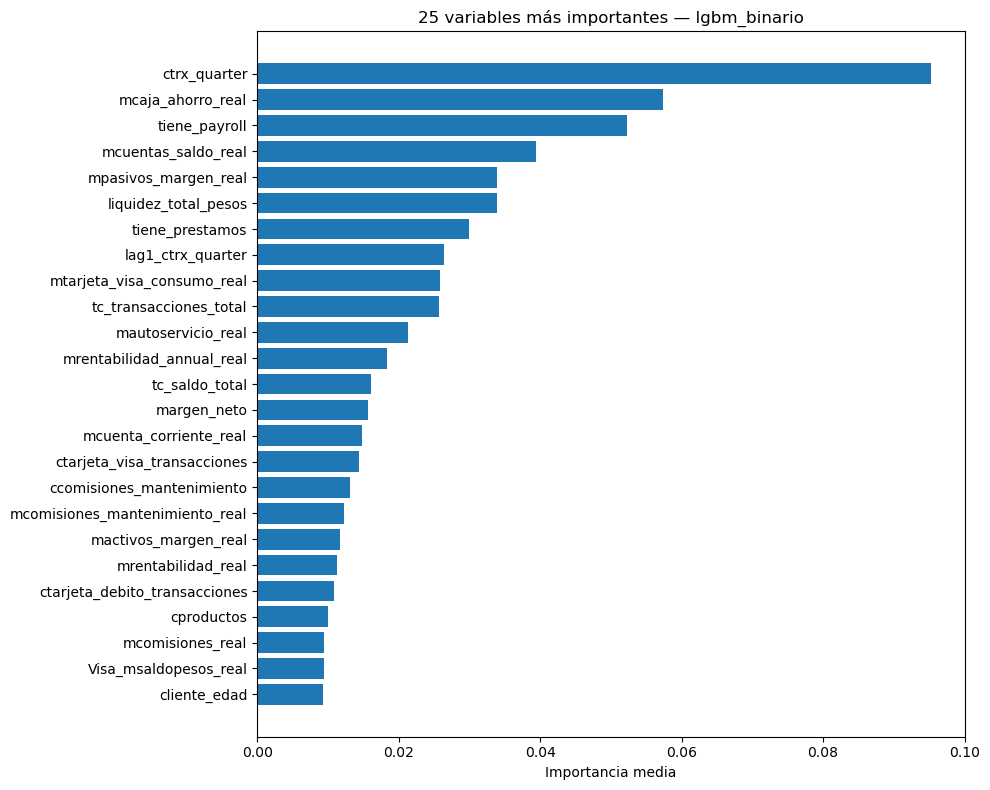

In [35]:
def importancias_semillero(modelos: list, nombres: list, algoritmo: str) -> pd.DataFrame:
    if algoritmo == "rf":
        imps = [m.feature_importances_ for m in modelos]
    else:
        imps = [m.feature_importance("gain") / max(m.feature_importance("gain").sum(), 1e-12) for m in modelos]
    return (pd.DataFrame({"variable": nombres, "importancia_media": np.mean(imps, axis=0)})
            .sort_values("importancia_media", ascending=False).reset_index(drop=True))


importancias = importancias_semillero(semillero_val, nombres_features, ALGORITMO)
print(importancias.head(25).to_string())

top = importancias.head(25).iloc[::-1]
plt.figure(figsize=(10, 8))
plt.barh(top["variable"], top["importancia_media"])
plt.xlabel("Importancia media")
plt.title(f"25 variables más importantes — {GANADOR}")
plt.tight_layout()
plt.show()

## Etapa 8 — Cantidad de envíos óptima (sobre 202106)

Se ordena 202106 por el score del semillero, se acumula la ganancia y se suaviza con una media
móvil. El corte es el máximo de la curva **suavizada** (el argmax crudo depende de 1–2 aciertos
sueltos). También se informa la **meseta**: el rango de envíos cuya ganancia suavizada está a menos
de 2 aciertos del máximo — cualquier cantidad dentro de ese rango es razonable.

In [36]:
def elegir_corte(score, y_true, ventana: int = VENTANA_SUAVIZADO, tolerancia: float = 2 * ganancia_acierto):
    orden, acum = curva_ganancia(score, y_true)
    suav = suavizar(acum, ventana)
    i = int(suav.argmax())
    meseta = np.where(suav >= suav[i] - tolerancia)[0]
    resumen = {
        "n_envios_optimo": i + 1,
        "ganancia_suavizada": float(suav[i]),
        "ganancia_real_en_ese_corte": float(acum[i]),
        "probabilidad_corte": float(np.asarray(score)[orden][i]),
        "meseta_desde": int(meseta.min()) + 1,
        "meseta_hasta": int(meseta.max()) + 1,
        "argmax_crudo": int(acum.argmax()) + 1,
        "ganancia_max_cruda": float(acum.max()),
    }
    tabla = pd.DataFrame({
        "posicion": np.arange(1, len(acum) + 1),
        "probabilidad": np.asarray(score)[orden],
        "ganancia_acumulada": acum,
        "ganancia_suavizada": suav,
    })
    return resumen, tabla


resumen_corte, tabla_ganancia = elegir_corte(score_valid, y_va)
for k, v in resumen_corte.items():
    print(f"  {k:28s}: {v:,.5f}" if isinstance(v, float) and v < 1 else f"  {k:28s}: {v:,.0f}")

  n_envios_optimo             : 12,496
  ganancia_suavizada          : 463,436,309
  ganancia_real_en_ese_corte  : 464,860,000
  probabilidad_corte          : 0.02736
  meseta_desde                : 11,625
  meseta_hasta                : 13,256
  argmax_crudo                : 12,508
  ganancia_max_cruda          : 466,730,000


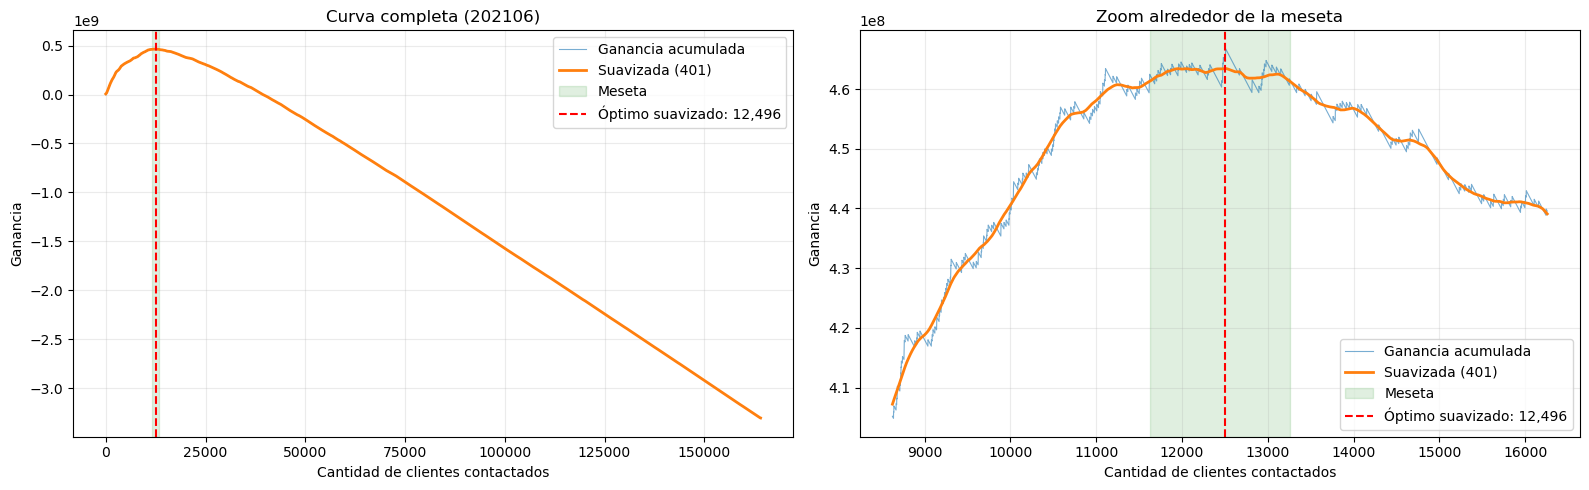

In [37]:
n_opt = resumen_corte["n_envios_optimo"]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (desde, hasta) in zip(axes, [(1, len(tabla_ganancia)),
                                     (max(1, resumen_corte["meseta_desde"] - 3000), resumen_corte["meseta_hasta"] + 3000)]):
    t = tabla_ganancia[tabla_ganancia["posicion"].between(desde, hasta)]
    ax.plot(t["posicion"], t["ganancia_acumulada"], lw=0.8, alpha=0.6, label="Ganancia acumulada")
    ax.plot(t["posicion"], t["ganancia_suavizada"], lw=2, label=f"Suavizada ({VENTANA_SUAVIZADO})")
    ax.axvspan(resumen_corte["meseta_desde"], resumen_corte["meseta_hasta"], color="green", alpha=0.12, label="Meseta")
    ax.axvline(n_opt, color="red", ls="--", label=f"Óptimo suavizado: {n_opt:,}")
    ax.set_xlabel("Cantidad de clientes contactados")
    ax.set_ylabel("Ganancia")
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_title("Curva completa (202106)")
axes[1].set_title("Zoom alrededor de la meseta")
plt.tight_layout()
plt.show()

In [38]:
# Tabla resumida: puntos equiespaciados + la fila del óptimo
pos = np.unique(np.append(np.linspace(0, len(tabla_ganancia) - 1, 40).astype(int), n_opt - 1))
print(tabla_ganancia.iloc[pos].assign(optimo=lambda d: d["posicion"] == n_opt)
      .round({"probabilidad": 5, "ganancia_suavizada": 0}).to_string(index=False))

 posicion  probabilidad  ganancia_acumulada  ganancia_suavizada  optimo
        1       0.88495              -27500        6.318022e+06   False
     4209       0.07832           298952500        2.992899e+08   False
     8417       0.04152           399932500        4.006320e+08   False
    12496       0.02736           464860000        4.634363e+08    True
    12625       0.02704           463512500        4.628898e+08   False
    16833       0.01933           429192500        4.297631e+08   False
    21041       0.01444           369572500        3.705244e+08   False
    25249       0.01128           300052500        3.009468e+08   False
    29457       0.00907           219532500        2.198589e+08   False
    33665       0.00749           129112500        1.280783e+08   False
    37873       0.00632            36492500        3.676133e+07   False
    42081       0.00541           -60527500       -6.050281e+07   False
    46289       0.00471          -165247500       -1.657413e+08 

## Etapa 9 — Reentrenamiento final (202103–202106) y predicción de agosto

Mismos hiperparámetros y mismas semillas del semillero, pero entrenando con **todos los meses con
target** (`MESES_FINAL`), incluido 202106: es el mes más parecido a agosto. El preprocesador (RF) se
vuelve a ajustar sobre ese mismo conjunto.

El corte se traslada **por cantidad**: los `n_envios_optimo` de 202106, reescalados por la cantidad
de clientes de agosto. (Con más datos de entrenamiento las probabilidades cambian de escala, así
que trasladar el valor de probabilidad no es confiable.) Podés pisarlo con `N_ENVIOS_MANUAL`,
idealmente con un valor dentro de la meseta.

In [39]:
N_ENVIOS_MANUAL = None

df_final = pd.concat([roles["train"], roles["validacion"]], ignore_index=True)
assert sorted(df_final[MES_COL].unique().tolist()) == sorted(MESES_FINAL)

prep_final, _ = preparar_preprocesador(ALGORITMO, df_final, columnas_modelo)
X_final = transformar(prep_final, df_final, columnas_modelo)
y_final = construir_y(df_final[TARGET_COL], TARGET)

t0 = time.time()
semillero_final = [entrenar(ALGORITMO, BEST_PARAMS, X_final, y_final, s) for s in SEMILLAS_SEMILLERO[:N_SEMILLERO]]
print(f"Semillero final ({MESES_FINAL}): {len(semillero_final)} modelos en {(time.time() - t0) / 60:.1f} min")

aplicacion = roles["aplicacion"]
X_ap = transformar(prep_final, aplicacion, columnas_modelo)
score_aplic = predecir_semillero(semillero_final, X_ap, ALGORITMO, TARGET)

n_envios = N_ENVIOS_MANUAL or int(round(n_opt * len(aplicacion) / len(roles["validacion"])))
orden_ap = np.argsort(-score_aplic, kind="mergesort")
prediccion_final = pd.DataFrame({ID_COL: aplicacion[ID_COL].to_numpy()[orden_ap][:n_envios]})

print(f"Envíos en agosto: {n_envios:,} de {len(aplicacion):,} clientes "
      f"({'manual' if N_ENVIOS_MANUAL else 'automático'}; meseta en 202106: "
      f"{resumen_corte['meseta_desde']:,}–{resumen_corte['meseta_hasta']:,})")
print(f"Probabilidad del último cliente contactado en agosto: {score_aplic[orden_ap][n_envios - 1]:.5f} "
      f"(en 202106 era {resumen_corte['probabilidad_corte']:.5f}; no tienen por qué coincidir)")

Semillero final ([202103, 202104, 202105, 202106]): 10 modelos en 7.2 min
Envíos en agosto: 12,537 de 164,647 clientes (automático; meseta en 202106: 11,625–13,256)
Probabilidad del último cliente contactado en agosto: 0.03125 (en 202106 era 0.02736; no tienen por qué coincidir)


In [40]:
def exportar_prediccion_final(prediccion: pd.DataFrame, carpeta: str = SALIDAS_PATH,
                               prefijo: str = "prediccion_baja_202108") -> str:
    """CSV para el submit: nombre único con timestamp, una sola columna, sin encabezado, IDs enteros."""
    n = len(prediccion)
    if not (8_000 <= n <= 15_000):
        print(f"OJO: {n:,} clientes — la campaña espera entre 8.000 y 15.000. Revisá el corte.")
    salida = prediccion[[ID_COL]].astype("int64")
    ts = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    ruta = os.path.join(carpeta, f"{prefijo}_{GANADOR}_{ts}.csv")
    salida.to_csv(ruta, index=False, header=False)

    # Registro de la corrida (para saber después con qué se generó cada submit)
    meta = {"archivo": os.path.basename(ruta), "modelo": GANADOR, "params": BEST_PARAMS,
            "meses_final": MESES_FINAL, "n_envios": n, "resumen_corte_202106": resumen_corte,
            "n_semillas": N_SEMILLERO, "n_features": len(columnas_modelo)}
    with open(ruta.replace(".csv", "_meta.json"), "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2, default=float)
    print(f"Guardado: {ruta} ({n:,} clientes, sin encabezado) + _meta.json")
    return ruta


if MODO_PRUEBA:
    print("MODO_PRUEBA: no se exporta el submit (los datos son una muestra). Poné MODO_PRUEBA = False.")
else:
    exportar_prediccion_final(prediccion_final)

Guardado: C:\Users\micaela.r.rodriguez\Documents\Mica\Personal\Data Mining\EyF\prediccion_baja_202108_lgbm_binario_20261005_195118.csv (12,537 clientes, sin encabezado) + _meta.json
